# SocialSentinel-AI: Tweet Dataset Inspection

**Objective**: Inspect and profile the tweet-level data in `data/raw/tweets.csv`.

This file contains tweet records, including tweet text, user IDs, engagement counts, and timestamps. It does not contain account profile features or bot labels, so this notebook focuses on tweet-level inspection rather than bot-versus-human classification.

## 1. Imports and Setup

Import the data and plotting tools, then build the CSV path relative to the project root so the notebook works from the repository or its `notebooks/` folder.

In [3]:
import os
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Set plotting aesthetics
%matplotlib inline
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['font.size'] = 11

# Project root directory
ROOT_DIR = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
RAW_DATA_FILE = ROOT_DIR / 'data' / 'raw' / 'tweets.csv'

print(f"Project root: {ROOT_DIR}")
print(f"CSV file: {RAW_DATA_FILE}")

Project root: /workspaces/Sentinal-AI-Applied-ML-Bot-Detection-Classification-Benchmark
CSV file: /workspaces/Sentinal-AI-Applied-ML-Bot-Detection-Classification-Benchmark/data/raw/tweets.csv


## 2. Load the Tweet CSV
Load `data/raw/tweets.csv` and preserve tweet and user IDs as strings. This avoids losing precision in large identifiers, which are keys for later grouping and joining.

In [6]:
if not RAW_DATA_FILE.is_file():
    raise FileNotFoundError(f"Tweet CSV not found: {RAW_DATA_FILE}")

tweets_df = pd.read_csv(
    RAW_DATA_FILE,
    low_memory=False,
    encoding='latin1',
    dtype={'id': 'string', 'user_id': 'string'},
)
print(f"Loaded {len(tweets_df):,} tweets from {RAW_DATA_FILE.name}")

Loaded 388,094 tweets from tweets.csv


## 3. High-Level Dataset Inspection & Summary

Preview rows and inspect row counts, column names, and data types to confirm the file loaded correctly and identify fields available for analysis.

In [7]:
if not tweets_df.empty:
    print("=== Head (First 5 records) ===")
    display(tweets_df.head())

    print("\n=== Info & Types ===")
    tweets_df.info()
else:
    print("The tweet CSV contains no records.")

=== Head (First 5 records) ===


,id,text,source,user_id,truncated,in_reply_to_status_id,in_reply_to_user_id,in_reply_to_screen_name,retweeted_status_id,geo,...,favorited,retweeted,possibly_sensitive,num_hashtags,num_urls,num_mentions,created_at,timestamp,crawled_at,updated
0,593932392663912449,RT @morningJewshow: Speaking about Jews and co...,"<a href=""http://tapbots.com/tweetbot"" rel=""nof...",678033,NaN,0.0,0.0,NaN,5.939322e+17,NaN,...,NaN,NaN,NaN,0.0,0.0,1.0,Fri May 01 00:18:11 +0000 2015,2015-05-01 02:18:11,2015-05-01 12:57:19,2015-05-01 12:57:19
1,593895316719423488,This age/face recognition thing..no reason pla...,"<a href=""http://twitter.com"" rel=""nofollow"">Tw...",678033,NaN,0.0,0.0,NaN,0.000000e+00,NaN,...,NaN,NaN,NaN,0.0,0.0,0.0,Thu Apr 30 21:50:52 +0000 2015,2015-04-30 23:50:52,2015-05-01 12:57:19,2015-05-01 12:57:19
2,593880638069018624,Only upside of the moment I can think of is th...,"<a href=""http://twitter.com"" rel=""nofollow"">Tw...",678033,NaN,0.0,0.0,NaN,0.000000e+00,NaN,...,NaN,NaN,NaN,2.0,0.0,0.0,Thu Apr 30 20:52:32 +0000 2015,2015-04-30 22:52:32,2015-05-01 12:57:19,2015-05-01 12:57:19
3,593847955536252928,If you're going to think about+create experien...,"<a href=""http://tapbots.com/tweetbot"" rel=""nof...",678033,NaN,0.0,0.0,NaN,0.000000e+00,NaN,...,NaN,NaN,NaN,2.0,0.0,0.0,Thu Apr 30 18:42:40 +0000 2015,2015-04-30 20:42:40,2015-05-01 12:57:19,2015-05-01 12:57:19
4,593847687847350272,Watching a thread on FB about possible future ...,"<a href=""http://tapbots.com/tweetbot"" rel=""nof...",678033,NaN,0.0,0.0,NaN,0.000000e+00,NaN,...,NaN,NaN,NaN,0.0,0.0,0.0,Thu Apr 30 18:41:36 +0000 2015,2015-04-30 20:41:36,2015-05-01 12:57:19,2015-05-01 12:57:19



=== Info & Types ===
<class 'pandas.DataFrame'>
RangeIndex: 388094 entries, 0 to 388093
Data columns (total 25 columns):
 #   Column                   Non-Null Count   Dtype  
---  ------                   --------------   -----  
 0   id                       388094 non-null  string 
 1   text                     386641 non-null  str    
 2   source                   388081 non-null  str    
 3   user_id                  388093 non-null  string 
 4   truncated                0 non-null       float64
 5   in_reply_to_status_id    388093 non-null  float64
 6   in_reply_to_user_id      388093 non-null  float64
 7   in_reply_to_screen_name  120006 non-null  str    
 8   retweeted_status_id      388093 non-null  float64
 9   geo                      18223 non-null   str    
 10  place                    23179 non-null   str    
 11  contributors             0 non-null       float64
 12  retweet_count            388093 non-null  float64
 13  reply_count              388093 non-null  float6

## 4. Missing Values Audit

Measure missing values by column. Use this evidence to decide which fields need cleaning, imputation, or removal; entirely empty columns cannot provide a useful model feature.

=== Missing Values Summary ===


,Missing Count,Missing %
contributors,388094,100.000000
crawled_at,1,0.000258
created_at,1,0.000258
favorite_count,1,0.000258
favorited,388094,100.000000
geo,369871,95.304488
in_reply_to_screen_name,268088,69.078110
in_reply_to_status_id,1,0.000258
in_reply_to_user_id,1,0.000258
num_hashtags,1,0.000258


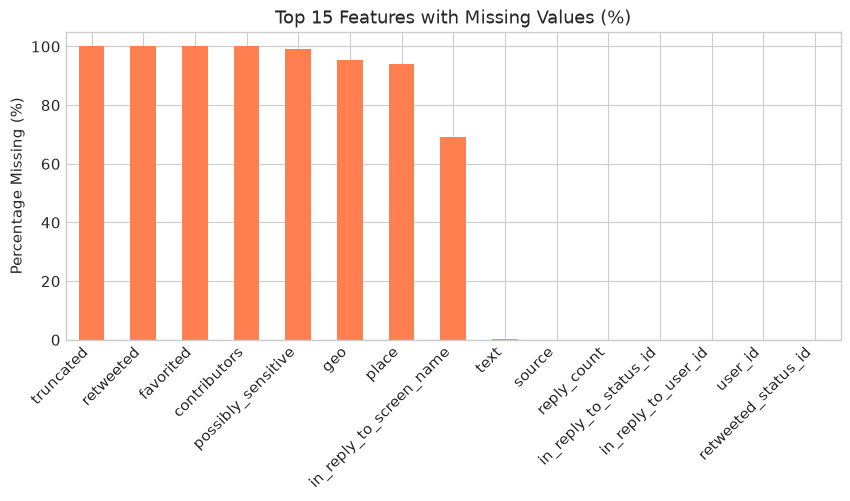

In [8]:
if not tweets_df.empty:
    null_pct = (tweets_df.isnull().sum() / len(tweets_df) * 100).sort_values(ascending=False)
    null_summary = pd.DataFrame({'Missing Count': tweets_df.isnull().sum(), 'Missing %': null_pct})
    print("=== Missing Values Summary ===")
    display(null_summary[null_summary['Missing Count'] > 0])

    plt.figure(figsize=(10, 4))
    null_pct.head(15).plot(kind='bar', color='coral')
    plt.title('Top 15 Features with Missing Values (%)')
    plt.ylabel('Percentage Missing (%)')
    plt.xticks(rotation=45, ha='right')
    plt.show()

## 5. Tweet Engagement Summary

Summarize retweets, replies, and favorites to understand observed interaction. These are descriptive statistics, not bot labels, and should only be used as model inputs if they are available at prediction time.

,count,mean,std,min,25%,50%,75%,max
retweet_count,388093.0,588.670868,12686.833312,0.0,0.0,0.0,1.0,3350099.0
reply_count,388093.0,0.000000,0.000000,0.0,0.0,0.0,0.0,0.0
favorite_count,388093.0,0.429060,4.090090,0.0,0.0,0.0,0.0,2182.0


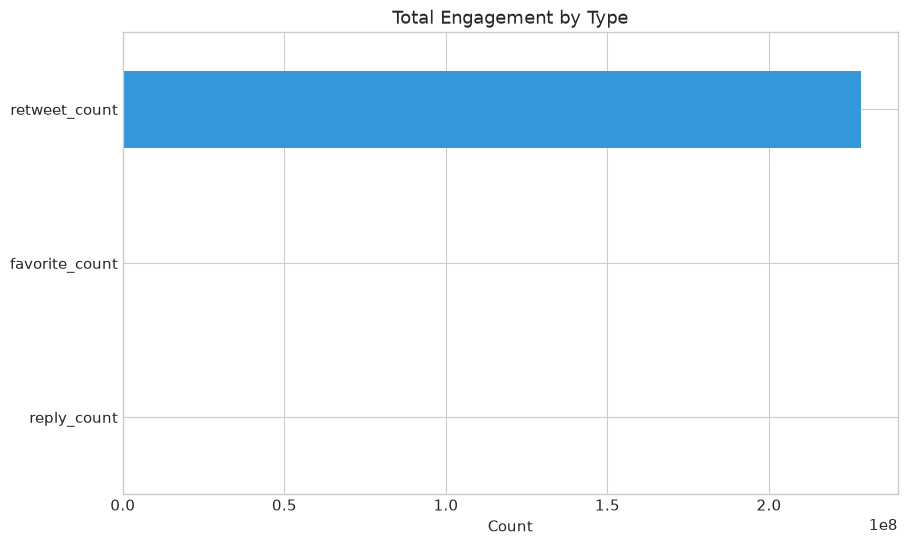

In [9]:
if not tweets_df.empty:
    engagement_cols = [
        col for col in ['retweet_count', 'reply_count', 'favorite_count']
        if col in tweets_df.columns
    ]
    if engagement_cols:
        engagement = tweets_df[engagement_cols].apply(pd.to_numeric, errors='coerce')
        display(engagement.describe().T)
        engagement.sum().sort_values().plot(kind='barh', color='#3498db')
        plt.title('Total Engagement by Type')
        plt.xlabel('Count')
        plt.show()
    else:
        print("No engagement count columns found in the CSV.")

## 6. Tweet Feature Analysis

This section summarizes numeric characteristics of individual tweets:
- **Engagement:** retweets, replies, and favorites indicate how much interaction a tweet received.
- **Content metadata:** hashtag, URL, and mention counts describe how each tweet is composed.
- **Feature distributions:** summary statistics show typical values and spread. A reproducible sample is shown on a `log1p` scale so highly skewed counts are easier to compare.
- **Posting timeline:** valid timestamps are grouped by month to show how tweet volume changes over time.

These are tweet-level observations, not account-level bot indicators. The CSV has no bot/human labels, so this analysis cannot compare bots with humans or establish that a feature identifies bots.

=== Tweet Feature Summary ===


,count,mean,std,min,25%,50%,75%,max
retweet_count,388093.0,588.670868,12686.833312,0.0,0.0,0.0,1.0,3350099.0
reply_count,388093.0,0.000000,0.000000,0.0,0.0,0.0,0.0,0.0
favorite_count,388093.0,0.429060,4.090090,0.0,0.0,0.0,0.0,2182.0
num_hashtags,388093.0,0.240901,0.665890,0.0,0.0,0.0,0.0,14.0
num_urls,388093.0,0.177656,0.388913,0.0,0.0,0.0,0.0,5.0
num_mentions,388093.0,0.807873,0.888699,0.0,0.0,1.0,1.0,12.0


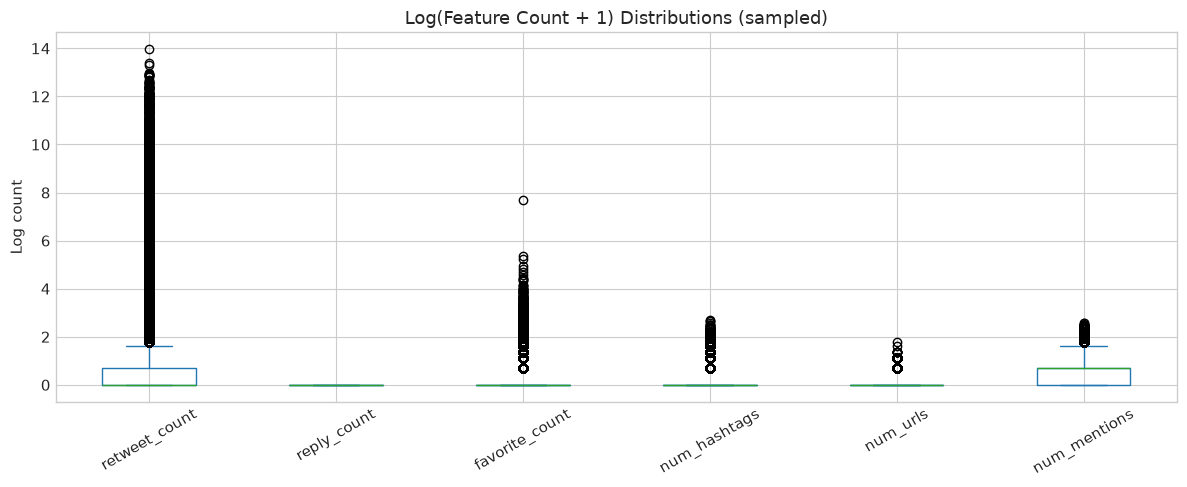

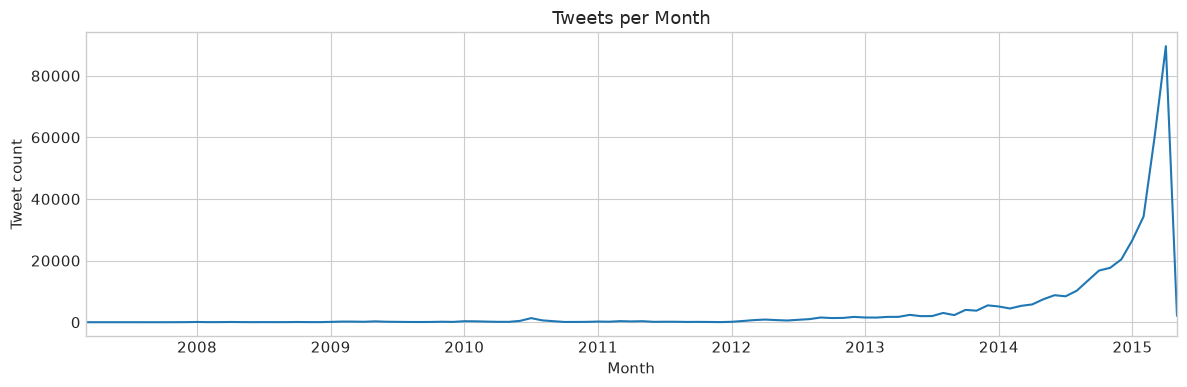

In [10]:
if not tweets_df.empty:
    numeric_cols = ['retweet_count', 'reply_count', 'favorite_count', 'num_hashtags', 'num_urls', 'num_mentions']
    valid_numeric = [col for col in numeric_cols if col in tweets_df.columns]

    for col in valid_numeric:
        tweets_df[col] = pd.to_numeric(tweets_df[col], errors='coerce')

    if valid_numeric:
        print("=== Tweet Feature Summary ===")
        display(tweets_df[valid_numeric].describe().T)

        sample = tweets_df[valid_numeric].sample(n=min(100_000, len(tweets_df)), random_state=42)
        sample.clip(lower=0).apply(np.log1p).plot(kind='box', figsize=(12, 5), rot=30)
        plt.title('Log(Feature Count + 1) Distributions (sampled)')
        plt.ylabel('Log count')
        plt.tight_layout()
        plt.show()
    else:
        print("No tweet count/metadata feature columns found in the CSV.")

    if 'timestamp' in tweets_df.columns:
        timestamps = pd.to_datetime(tweets_df['timestamp'], errors='coerce')
        tweets_per_month = timestamps.dt.to_period('M').value_counts().sort_index()
        tweets_per_month.plot(figsize=(12, 4))
        plt.title('Tweets per Month')
        plt.xlabel('Month')
        plt.ylabel('Tweet count')
        plt.tight_layout()
        plt.show()

## 7. Next Steps & Feature Engineering Plan
Turn tweet-level records into account-level features, then obtain trusted account labels before attempting bot classification.
- [ ] Aggregate tweet-level features by `user_id`.
- [ ] Join account-level profile data and ground-truth labels before training a bot classifier.
- [ ] Build baseline classification models only after labeled account data is available.

## 8. Applying Machine Learning Theory in Practice

A practical bot-detection pipeline applies the theory in this order:

1. **Define the prediction unit and target:** predict whether an account is a bot; obtain verified `is_bot` labels. The current tweets CSV has no such label, so it supports EDA and feature engineering but not supervised training yet.
2. **Engineer account-level features:** group tweets by `user_id` and calculate activity and content measures (for example, tweets per day, average hashtags, URLs, mentions, and engagement). Use only data available before the prediction time; exclude IDs and post-outcome fields to prevent leakage.
3. **Prepare a fair evaluation:** split by account, not by individual tweet, so tweets from one account cannot appear in both train and test sets. For future-time predictions, use a chronological split. Fit imputation, scaling, and feature selection on training data only.
4. **Train simple baselines:** compare a majority-class baseline with logistic regression (scaled numeric features) and a tree-based model (nonlinear patterns). Tune choices using training-only cross-validation; use class weights if labels are imbalanced.
5. **Evaluate for the real use case:** report precision, recall, F1, a confusion matrix, and precision-recall AUC. Select a threshold based on the cost of false bot flags versus missed bots; do not rely on accuracy alone when classes are imbalanced.
6. **Check generalization:** inspect errors by account group and time period, then test on a genuinely held-out set. Monitor data and performance drift after deployment.

The current notebook completes the early data-understanding stage. A labeled account dataset is required to demonstrate model fitting and meaningful classification metrics.